<a href="https://colab.research.google.com/github/CiaraFarrellSETU/phd/blob/main/Tur_Hyd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Load the CSV file path into a pandas DataFrame
df = pd.read_csv('/content/20230804165658_combined_results_out.csv')
df.head()

,Unnamed: 0,001BREDRM,002CPLUNK,003BRIFLD,005CRWREA,006RATNUL,007CARWKL,008BLGLDA,009BALTUR,010LISDUF,...,861TOOLSx,862LGARR2,863NUTFLD,864BALGFN,867BTEIGE,870CARROW,871CLOONN,872BBUCKS,873NGROVE,874NGROVW
0,2015-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df.rename(columns={df.columns[0]: 'Date'}, inplace=True)
df.head()

,Date,001BREDRM,002CPLUNK,003BRIFLD,005CRWREA,006RATNUL,007CARWKL,008BLGLDA,009BALTUR,010LISDUF,...,861TOOLSx,862LGARR2,863NUTFLD,864BALGFN,867BTEIGE,870CARROW,871CLOONN,872BBUCKS,873NGROVE,874NGROVW
0,2015-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saving 20230804165658_combined_results_out.csv to 20230804165658_combined_results_out (1).csv

Successfully loaded: 20230804165658_combined_results_out (1).csv
Original Wide DataFrame Shape: (2923, 463)
Reshaped Long DataFrame Shape: (1350426, 3)


,Date,Turlough_ID,Water_Level
0,2015-01-01,001BREDRM,NaN
1,2015-01-02,001BREDRM,NaN
2,2015-01-03,001BREDRM,NaN
3,2015-01-04,001BREDRM,NaN
4,2015-01-05,001BREDRM,NaN
5,2015-01-06,001BREDRM,NaN
6,2015-01-07,001BREDRM,NaN
7,2015-01-08,001BREDRM,NaN
8,2015-01-09,001BREDRM,NaN
9,2015-01-10,001BREDRM,NaN



--- Water Level Statistics ---
count    1.350426e+06
mean     4.268108e+01
std      2.722724e+01
min      9.167523e-01
25%      2.004015e+01
50%      3.692572e+01
75%      6.240517e+01
max      1.302726e+02
Name: Water_Level_Clean, dtype: float64


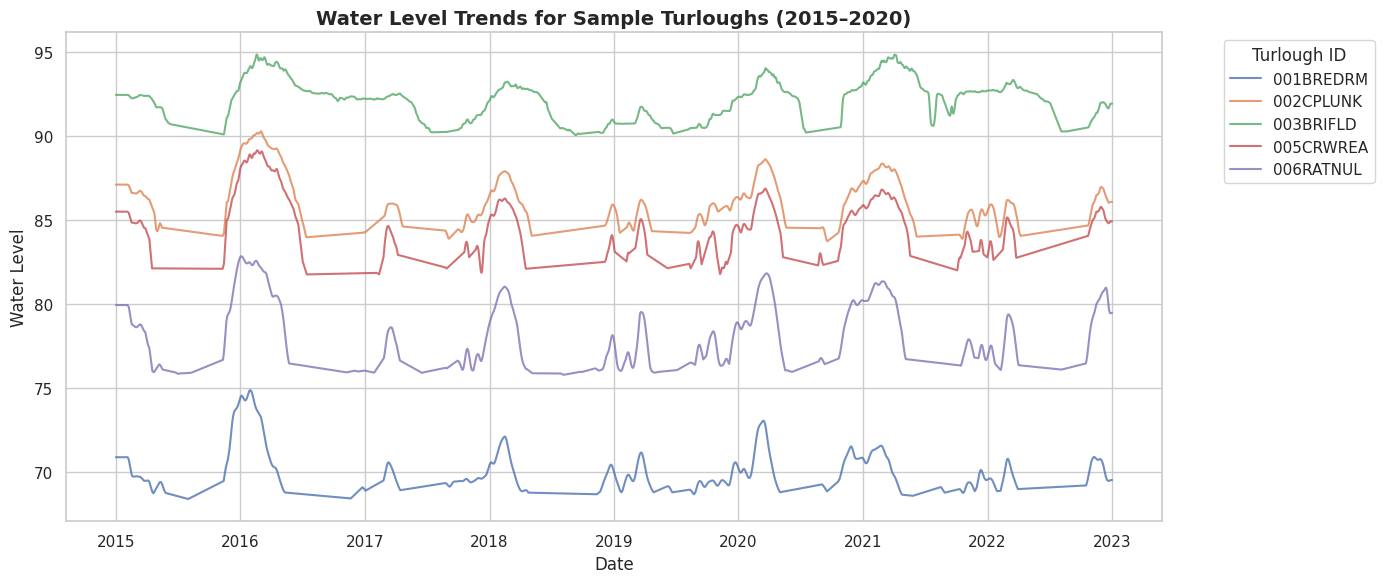

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner plots
sns.set_theme(style="whitegrid")

# 1. Upload your CSV file directly in Colab
from google.colab import files
uploaded = files.upload()

# Get the filename automatically from the uploaded files
filename = list(uploaded.keys())[0]
print(f"\nSuccessfully loaded: {filename}")

# Load the dataset
df = pd.read_csv(filename)
print(f"Original Wide DataFrame Shape: {df.shape}")

# 2. Reshape from Wide to Long Format
# Assuming the first column is the Date and the rest are Turlough IDs
date_col = df.columns[0]
turlough_cols = df.columns[1:]

df_long = df.melt(
    id_vars=[date_col],
    value_vars=turlough_cols,
    var_name='Turlough_ID',
    value_name='Water_Level'
)

# Rename date column and ensure proper data types
df_long = df_long.rename(columns={date_col: 'Date'})
df_long['Date'] = pd.to_datetime(df_long['Date'], errors='coerce')
df_long['Water_Level'] = pd.to_numeric(df_long['Water_Level'], errors='coerce')

# Sort chronologically by turlough
df_long = df_long.sort_values(['Turlough_ID', 'Date']).reset_index(drop=True)

print(f"Reshaped Long DataFrame Shape: {df_long.shape}")
display(df_long.head(10))

# 3. Handle Missing Values (Interpolation per Turlough)
# Turlough water data often has gaps due to dry periods or logger maintenance.
# Linear interpolation fills small gaps while preserving overall trends.
df_long['Water_Level_Clean'] = df_long.groupby('Turlough_ID')['Water_Level'].transform(
    lambda x: x.interpolate(method='linear', limit_direction='both')
)

# Summary statistics of the cleaned data
print("\n--- Water Level Statistics ---")
print(df_long['Water_Level_Clean'].describe())

# 4. Plot Time Series Trends for a Few Sample Turloughs
# Pick the first 5 active turloughs with data
sample_ids = df_long['Turlough_ID'].dropna().unique()[:5]

plt.figure(figsize=(14, 6))
for t_id in sample_ids:
    subset = df_long[df_long['Turlough_ID'] == t_id]
    plt.plot(subset['Date'], subset['Water_Level_Clean'], label=t_id, alpha=0.8, linewidth=1.5)

plt.title('Water Level Trends for Sample Turloughs (2015–2020)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Water Level', fontsize=12)
plt.legend(title='Turlough ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

--- 1. Calculating Hydroperiods (2015-2020) ---
   Year  Days_Flooded
0  2015         365.0
1  2016         366.0
2  2017         365.0
3  2018         365.0
4  2019         365.0
5  2020         366.0
6  2021         365.0
7  2022         365.0
8  2023           1.0


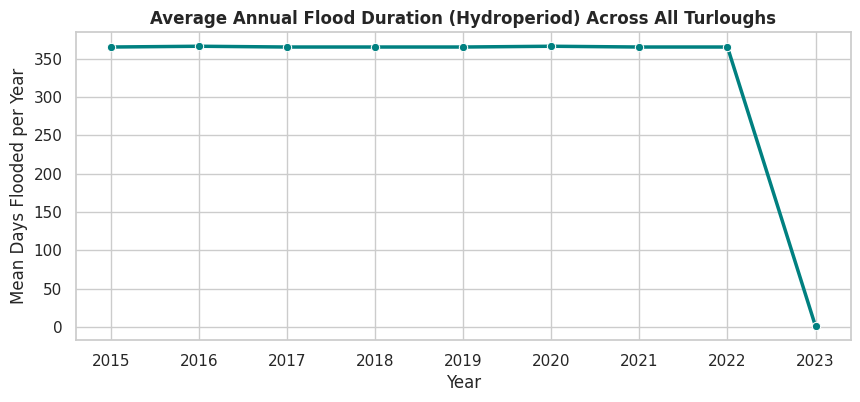

In [4]:
# Ensure 'Date' is datetime and data is sorted
df_long['Date'] = pd.to_datetime(df_long['Date'])
df_long = df_long.sort_values(['Turlough_ID', 'Date']).reset_index(drop=True)

# Extract Year for annual analysis
df_long['Year'] = df_long['Date'].dt.year

# ==========================================
# 1. FLOOD DURATION & FREQUENCY (HYDROPERIOD)
# ==========================================
print("--- 1. Calculating Hydroperiods (2015-2020) ---")

# Define a flooding threshold (adjust based on your datum, e.g., > 0 meters or above baseline)
FLOOD_THRESHOLD = 0.05
df_long['Is_Flooded'] = df_long['Water_Level_Clean'] > FLOOD_THRESHOLD

# Sum up days flooded per turlough per year
hydroperiod = df_long.groupby(['Turlough_ID', 'Year'])['Is_Flooded'].sum().reset_index()
hydroperiod = hydroperiod.rename(columns={'Is_Flooded': 'Days_Flooded'})

# Display average hydroperiod across all turloughs per year
avg_hydroperiod = hydroperiod.groupby('Year')['Days_Flooded'].mean().reset_index()
print(avg_hydroperiod)

# Plot average hydroperiod trend across the years
plt.figure(figsize=(10, 4))
sns.lineplot(data=avg_hydroperiod, x='Year', y='Days_Flooded', marker='o', color='teal', linewidth=2.5)
plt.title('Average Annual Flood Duration (Hydroperiod) Across All Turloughs', fontsize=12, fontweight='bold')
plt.ylabel('Mean Days Flooded per Year')
plt.xlabel('Year')
plt.show()


--- 2. Analyzing Extreme Weather Windows ---


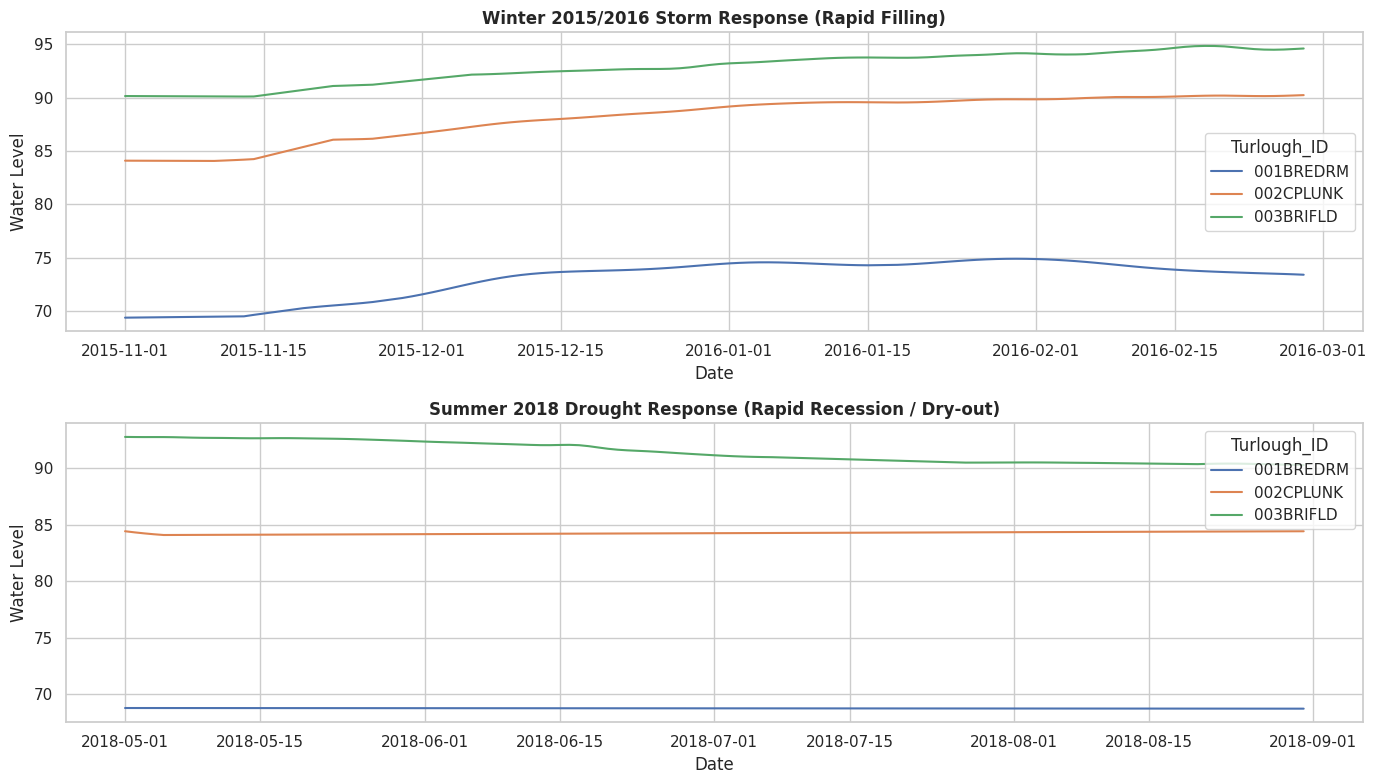

In [5]:
# ==========================================
# 2. EXTREME WEATHER IMPACT (E.g., Winter 2015 vs Summer 2018)
# ==========================================
print("\n--- 2. Analyzing Extreme Weather Windows ---")

# Let's isolate two notable Irish climate events:
# 1. Winter Storm Desmond / heavy winter flooding (Dec 2015 - Jan 2016)
# 2. Severe summer drought (June - July 2018)

storm_period = df_long[(df_long['Date'] >= '2015-11-01') & (df_long['Date'] <= '2016-02-28')]
drought_period = df_long[(df_long['Date'] >= '2018-05-01') & (df_long['Date'] <= '2018-08-31')]

# Pick 3 sample turloughs to visualize their extreme response
sample_turloughs = df_long['Turlough_ID'].unique()[:3]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=False)

# Plot Storm Response
subset_storm = storm_period[storm_period['Turlough_ID'].isin(sample_turloughs)]
sns.lineplot(data=subset_storm, x='Date', y='Water_Level_Clean', hue='Turlough_ID', ax=axes[0], linewidth=1.5)
axes[0].setTitle = axes[0].set_title('Winter 2015/2016 Storm Response (Rapid Filling)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Water Level')

# Plot Drought Response
subset_drought = drought_period[drought_period['Turlough_ID'].isin(sample_turloughs)]
sns.lineplot(data=subset_drought, x='Date', y='Water_Level_Clean', hue='Turlough_ID', ax=axes[1], linewidth=1.5)
axes[1].set_title('Summer 2018 Drought Response (Rapid Recession / Dry-out)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Water Level')

plt.tight_layout()
plt.show()


--- 3. Calculating Aquifer Filling & Recession Rates ---
Average Daily Filling Velocity: 0.0134 units/day
Average Daily Recession Velocity: -0.0143 units/day


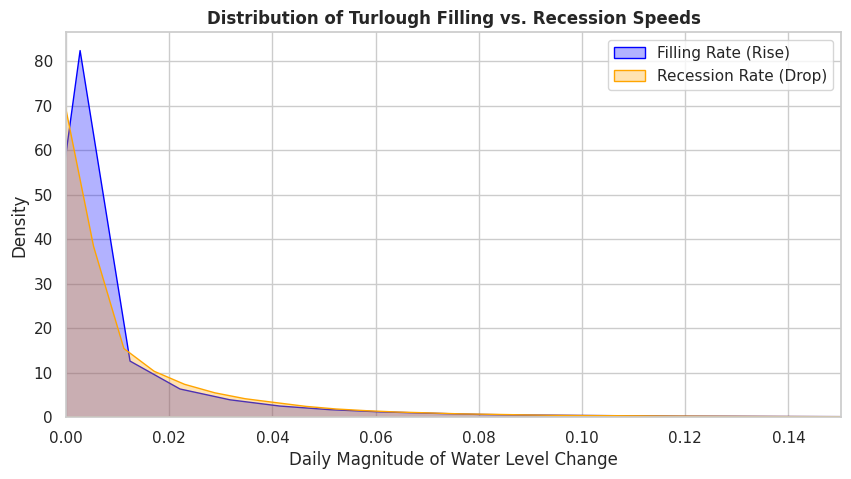

In [6]:
print("\n--- 3. Calculating Aquifer Filling & Recession Rates ---")

# Calculate daily water level change (first derivative)
df_long['Daily_Rate'] = df_long.groupby('Turlough_ID')['Water_Level_Clean'].diff()

# Separate filling rates (positive velocity) and recession rates (negative velocity)
filling_rates = df_long[df_long['Daily_Rate'] > 0]['Daily_Rate']
recession_rates = df_long[df_long['Daily_Rate'] < 0]['Daily_Rate']

print(f"Average Daily Filling Velocity: {filling_rates.mean():.4f} units/day")
print(f"Average Daily Recession Velocity: {recession_rates.mean():.4f} units/day")

# Plot distribution of rates to compare aquifer responsiveness
plt.figure(figsize=(10, 5))
sns.kdeplot(filling_rates, label='Filling Rate (Rise)', color='blue', fill=True, alpha=0.3)
sns.kdeplot(recession_rates.abs(), label='Recession Rate (Drop)', color='orange', fill=True, alpha=0.3)
plt.xlim(0, filling_rates.quantile(0.99)) # Clip extreme outliers for clean view
plt.title('Distribution of Turlough Filling vs. Recession Speeds', fontsize=12, fontweight='bold')
plt.xlabel('Daily Magnitude of Water Level Change')
plt.ylabel('Density')
plt.legend()
plt.show()

In [7]:
import pandas as pd

# Group by Turlough_ID and calculate site-specific rates
site_rates = df_long.groupby('Turlough_ID').agg(
    Avg_Filling_Rate=('Daily_Rate', lambda x: x[x > 0].mean()),
    Avg_Recession_Rate=('Daily_Rate', lambda x: x[x < 0].mean()),
    Max_Daily_Rise=('Daily_Rate', 'max'),
    Max_Daily_Drop=('Daily_Rate', 'min')
).reset_index()

# Display the top 15 rows sorted by fastest average filling speed
display(site_rates.sort_values(by='Avg_Filling_Rate', ascending=False).head(15))

,Turlough_ID,Avg_Filling_Rate,Avg_Recession_Rate,Max_Daily_Rise,Max_Daily_Drop
32,039BLKRCK,0.179077,-0.172995,1.912246,-1.157093
35,042LGHCOY,0.137994,-0.125847,0.930005,-0.811104
47,057LALNUN,0.120706,-0.137722,0.947053,-0.609050
38,045GRYLND,0.095109,-0.113166,0.933712,-1.002004
37,044COOLEx,0.085872,-0.074006,0.740495,-0.465037
36,043CAHGLS,0.079180,-0.070413,0.411930,-0.330642
40,047HWKHIL,0.075692,-0.081310,0.654130,-0.653259
79,130MOYLAN,0.071951,-0.065347,0.347605,-0.270475
137,255KILMUR,0.064508,-0.044427,0.563901,-0.505068
358,697TURNAG,0.060319,-0.063471,0.443080,-0.207332


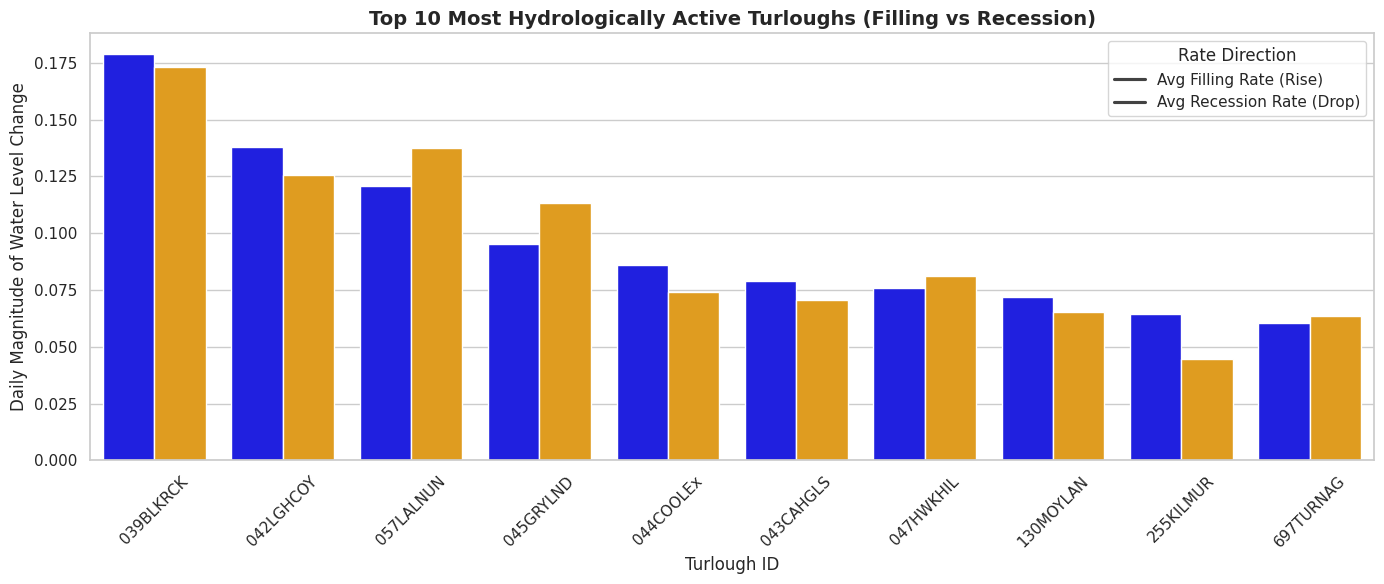

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select top 10 fastest responding turloughs for visualization
top_10_responders = site_rates.sort_values(by='Avg_Filling_Rate', ascending=False).head(10)

# Melt for easy side-by-side barplot visualization
top_10_melted = top_10_responders.melt(
    id_vars=['Turlough_ID'],
    value_vars=['Avg_Filling_Rate', 'Avg_Recession_Rate'],
    var_name='Rate_Type',
    value_name='Velocity'
)
top_10_melted['Velocity_Abs'] = top_10_melted['Velocity'].abs()

plt.figure(figsize=(14, 6))
sns.barplot(
    data=top_10_melted,
    x='Turlough_ID',
    y='Velocity_Abs',
    hue='Rate_Type',
    palette={'Avg_Filling_Rate': 'blue', 'Avg_Recession_Rate': 'orange'}
)

plt.title('Top 10 Most Hydrologically Active Turloughs (Filling vs Recession)', fontsize=14, fontweight='bold')
plt.ylabel('Daily Magnitude of Water Level Change')
plt.xlabel('Turlough ID')
plt.legend(title='Rate Direction', labels=['Avg Filling Rate (Rise)', 'Avg Recession Rate (Drop)'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

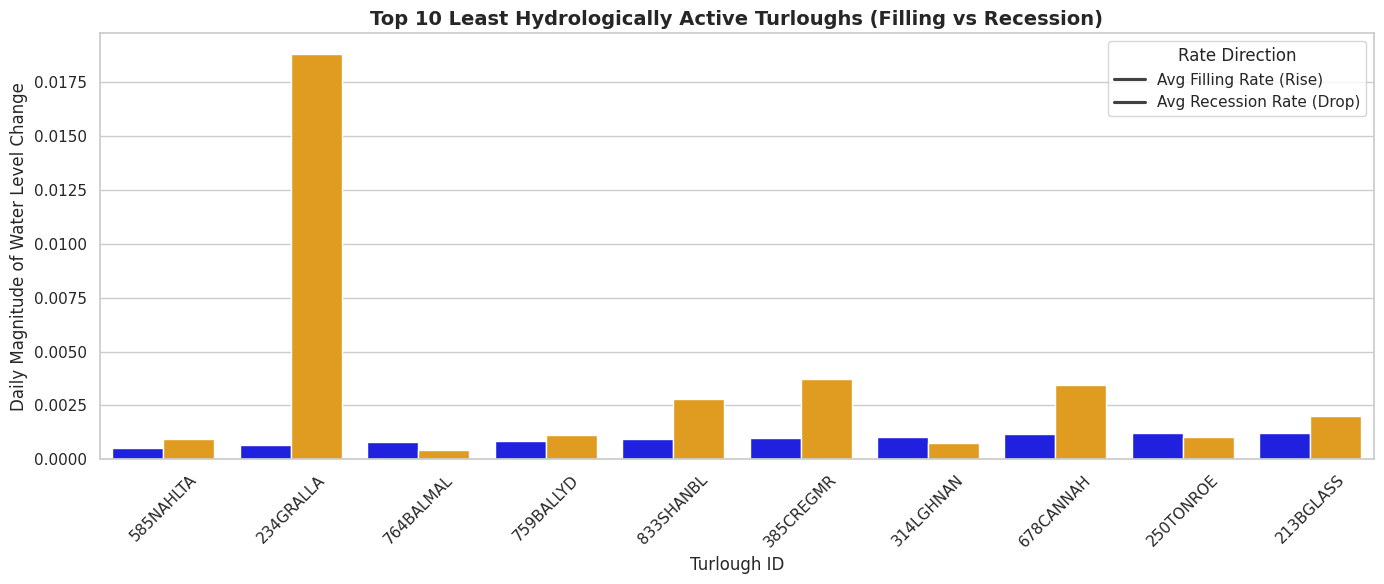

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select top 10 slowest responding turloughs for visualization
bottom_10_responders = site_rates.sort_values(by='Avg_Filling_Rate', ascending=True).head(10)

# Melt for easy side-by-side barplot visualization
top_10_melted = bottom_10_responders.melt(
    id_vars=['Turlough_ID'],
    value_vars=['Avg_Filling_Rate', 'Avg_Recession_Rate'],
    var_name='Rate_Type',
    value_name='Velocity'
)
top_10_melted['Velocity_Abs'] = top_10_melted['Velocity'].abs()

plt.figure(figsize=(14, 6))
sns.barplot(
    data=top_10_melted,
    x='Turlough_ID',
    y='Velocity_Abs',
    hue='Rate_Type',
    palette={'Avg_Filling_Rate': 'blue', 'Avg_Recession_Rate': 'orange'}
)

plt.title('Top 10 Least Hydrologically Active Turloughs (Filling vs Recession)', fontsize=14, fontweight='bold')
plt.ylabel('Daily Magnitude of Water Level Change')
plt.xlabel('Turlough ID')
plt.legend(title='Rate Direction', labels=['Avg Filling Rate (Rise)', 'Avg Recession Rate (Drop)'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Matrix shape after dropping sparse turloughs: (2923, 462)

--- 2. Extracting Features & Running K-Means Clustering ---
Clustering complete. Distribution of turloughs per cluster:
Cluster
0    221
3    142
1     78
2     21
Name: count, dtype: int64


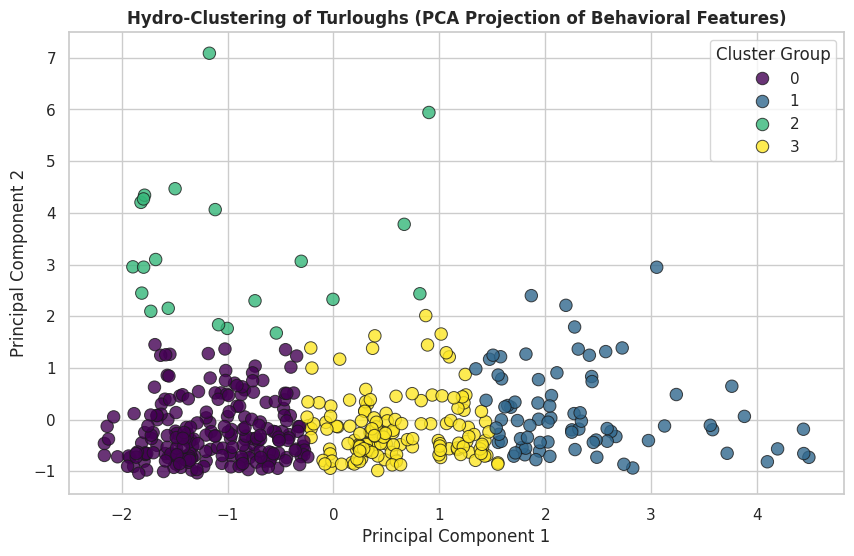


--- 3. Analyzing Subterranean Groundwater Connectivity ---

Found 6396 highly synchronized turlough pairs (r > 0.85).
Top 10 most synchronized pairs (potential underground conduit links):


,Turlough_A,Turlough_B,Correlation
18054,046NEWTWN,043CAHGLS,0.985487
22686,059KNOCRO,058LGEALN,0.981400
18516,047HWKHIL,043CAHGLS,0.980280
176070,741KNOROE,058LGEALN,0.973932
16669,043CAHGLS,044COOLEx,0.973214
18058,046NEWTWN,047HWKHIL,0.972544
159424,668POULAT,041CHRMOR,0.969693
176071,741KNOROE,059KNOCRO,0.969584
184330,762BALLIA,863NUTFLD,0.969557
156190,660RAHEEN,041CHRMOR,0.969432


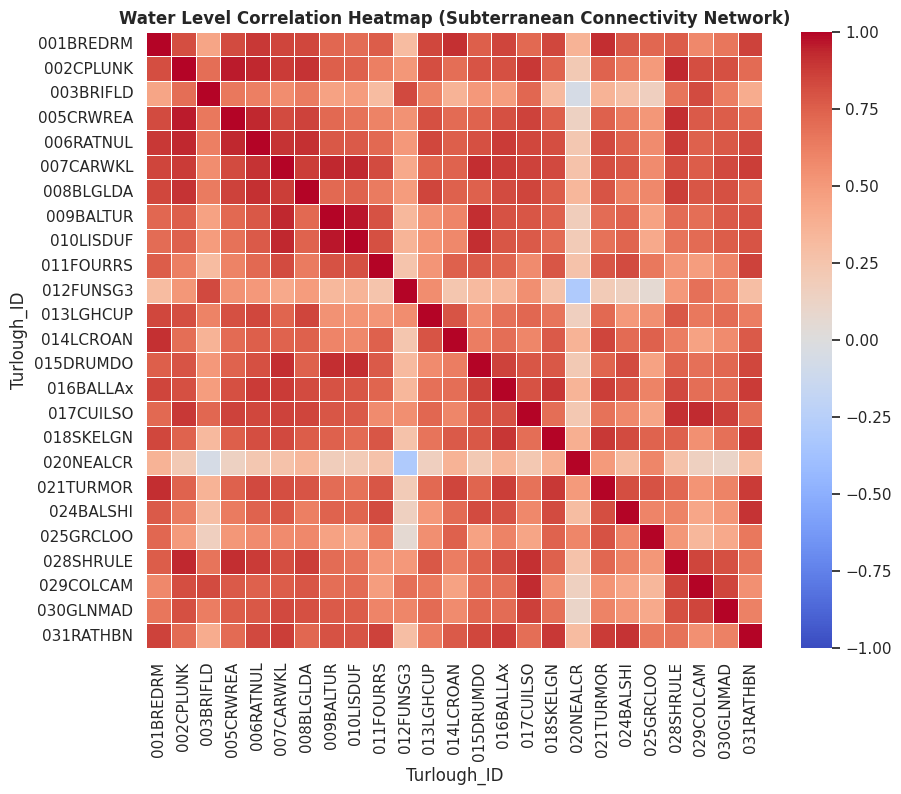

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

# Ensure clean datetime sorting
df_long['Date'] = pd.to_datetime(df_long['Date'])

# 1. Pivot data to Date x Turlough_ID matrix
df_pivot = df_long.pivot(index='Date', columns='Turlough_ID', values='Water_Level_Clean')

# Drop turloughs with excessive missing data (e.g., more than 50% missing values)
threshold = len(df_pivot) * 0.5
df_pivot = df_pivot.dropna(axis=1, thresh=threshold)
print(f"Matrix shape after dropping sparse turloughs: {df_pivot.shape}")

# Fill remaining minor gaps via interpolation for clustering accuracy
df_pivot = df_pivot.interpolate(method='linear', limit_direction='both').fillna(0)


# ==========================================
# 2. HYDRO-CLUSTERING (UNSUPERVISED MACHINE LEARNING)
# ==========================================
print("\n--- 2. Extracting Features & Running K-Means Clustering ---")

# Extract robust hydrological features for each turlough
features = pd.DataFrame(index=df_pivot.columns)
features['Mean_Level'] = df_pivot.mean()
features['Max_Level'] = df_pivot.max()
features['Std_Level'] = df_pivot.std()
features['Flood_Frequency'] = (df_pivot > 0.05).mean() # Proportion of days flooded

# Handle any potential NaNs in features
features = features.fillna(0)

# Scale features for machine learning
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Run K-Means Clustering (let's test for 4 distinct hydrological behavior types)
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
features['Cluster'] = kmeans.fit_predict(features_scaled)

print(f"Clustering complete. Distribution of turloughs per cluster:")
print(features['Cluster'].value_counts())

# Visualize clusters using PCA dimensionality reduction (2D projection)
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(features_scaled)
features['PCA1'] = pca_coords[:, 0]
features['PCA2'] = pca_coords[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=features, x='PCA1', y='PCA2', hue='Cluster',
    palette='viridis', s=80, alpha=0.8, edgecolor='k'
)
plt.title("Hydro-Clustering of Turloughs (PCA Projection of Behavioral Features)", fontsize=12, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster Group')
plt.show()


# ==========================================
# 3. GROUNDWATER CONNECTIVITY MAPPING (CORRELATION)
# ==========================================
print("\n--- 3. Analyzing Subterranean Groundwater Connectivity ---")

# Compute Pearson correlation matrix across all turlough time series
corr_matrix = df_pivot.corr()

# Rename index to avoid name collision with columns ('Turlough_ID') on unstack
corr_matrix.index.rename('Turlough_A_Temp', inplace=True)
corr_unstacked = corr_matrix.unstack().reset_index()
corr_unstacked.columns = ['Turlough_A', 'Turlough_B', 'Correlation']

# Filter out self-pairs and duplicates
conduits = corr_unstacked[
    (corr_unstacked['Turlough_A'] != corr_unstacked['Turlough_B']) &
    (corr_unstacked['Correlation'] > 0.85)
]

# Sort by highest correlation
conduits = conduits.sort_values(by='Correlation', ascending=False).drop_duplicates(subset=['Correlation'])

print(f"\nFound {len(conduits)} highly synchronized turlough pairs (r > 0.85).")
print("Top 10 most synchronized pairs (potential underground conduit links):")
display(conduits.head(10))

# Plot correlation heatmap for a subset of turloughs to visualize networks
plt.figure(figsize=(10, 8))
sample_subset = df_pivot.columns[:25] # First 25 turloughs for legibility
sns.heatmap(df_pivot[sample_subset].corr(), cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Water Level Correlation Heatmap (Subterranean Connectivity Network)', fontsize=12, fontweight='bold')
plt.show()

Original Missing Values in Matrix: 0 total NaN entries.

Running KNN Imputation across spatial neighbors... (this may take a few seconds)
Remaining Missing Values after KNN Imputation: 0

No missing values found! Showing results for the first station: 001BREDRM


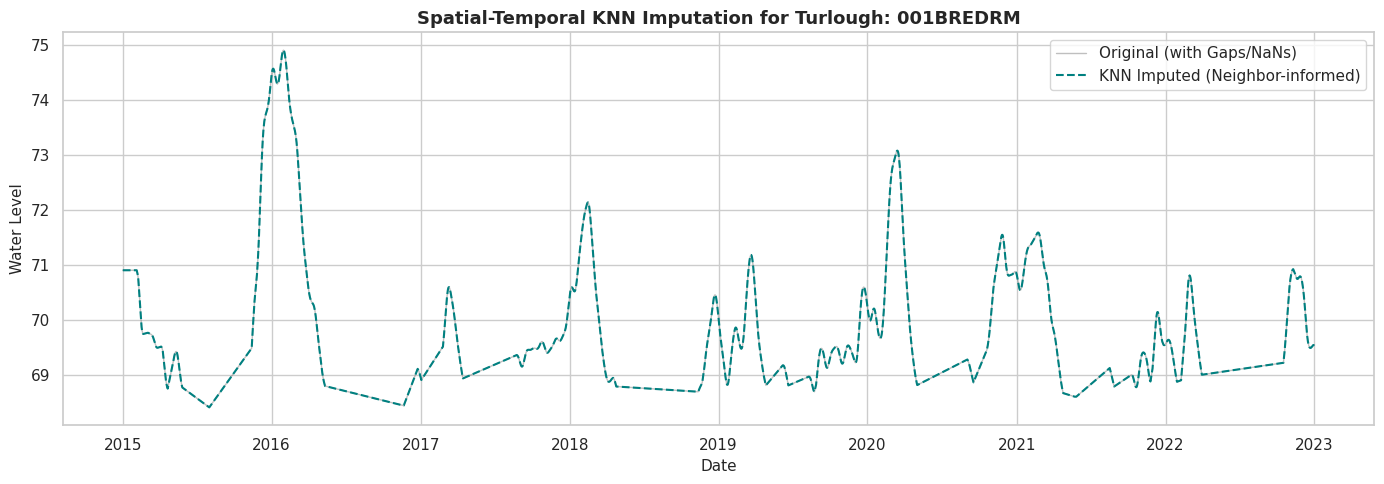


Cleaned long-format dataset ready for advanced modeling:


,Date,Turlough_ID,Water_Level_Imputed
0,2015-01-01,001BREDRM,70.906616
1,2015-01-02,001BREDRM,70.906616
2,2015-01-03,001BREDRM,70.906616
3,2015-01-04,001BREDRM,70.906616
4,2015-01-05,001BREDRM,70.906616
...,...,...,...
120,2015-05-01,001BREDRM,69.112794
121,2015-05-02,001BREDRM,69.148022
122,2015-05-03,001BREDRM,69.183250
123,2015-05-04,001BREDRM,69.218478


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer

sns.set_theme(style="whitegrid")

# Ensure df_pivot is ready (Rows = Dates, Columns = Turloughs)
# If not already defined from previous steps, recreate it:
if 'df_pivot' not in globals():
    df_long['Date'] = pd.to_datetime(df_long['Date'])
    df_pivot = df_long.pivot(index='Date', columns='Turlough_ID', values='Water_Level')

print(f"Original Missing Values in Matrix: {df_pivot.isna().sum().sum():,} total NaN entries.")

# ==========================================
# 1. TRANSPOSE FOR SPATIAL KNN IMPUTATION
# ==========================================
# KNNImputer looks at rows as samples and columns as features.
# By transposing so Rows = Turloughs and Columns = Dates,
# the model finds turloughs with similar temporal trajectories to fill gaps.
df_turlough_time = df_pivot.T

# Initialize KNN Imputer (using 5 nearest neighbor turloughs, weighted by distance)
imputer = KNNImputer(n_neighbors=5, weights='distance')

print("\nRunning KNN Imputation across spatial neighbors... (this may take a few seconds)")
imputed_array = imputer.fit_transform(df_turlough_time)

# Convert back to DataFrame with original index and columns
df_imputed_wide = pd.DataFrame(
    imputed_array,
    index=df_turlough_time.index,
    columns=df_turlough_time.columns
).T

print(f"Remaining Missing Values after KNN Imputation: {df_imputed_wide.isna().sum().sum()}")


# ==========================================
# 2. EVALUATE & VISUALIZE THE IMPUTATION
# ==========================================
# Let's pick a turlough that had missing values and compare
# original sparse data vs. KNN-imputed data

# Find a turlough with missing values in the original set
missing_counts = df_pivot.isna().sum()
columns_with_missing = missing_counts[missing_counts > 0].index

if len(columns_with_missing) > 0:
    sample_target = columns_with_missing[0]
else:
    # Fallback to the first available turlough if there were no missing values
    sample_target = df_pivot.columns[0]
    print(f"\nNo missing values found! Showing results for the first station: {sample_target}")

plt.figure(figsize=(14, 5))

# Plot original data (with gaps)
plt.plot(
    df_pivot.index, df_pivot[sample_target],
    label='Original (with Gaps/NaNs)', color='gray', alpha=0.5, linewidth=1
)

# Plot KNN-imputed data (filled)
plt.plot(
    df_imputed_wide.index, df_imputed_wide[sample_target],
    label='KNN Imputed (Neighbor-informed)', color='teal', linestyle='--', linewidth=1.5
)

plt.title(f'Spatial-Temporal KNN Imputation for Turlough: {sample_target}', fontsize=13, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Water Level', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


# ==========================================
# 3. EXPORT CLEANED DATASET
# ==========================================
# Melt back to long format for downstream machine learning or modeling
df_final_clean = df_imputed_wide.melt(ignore_index=False).reset_index()
df_final_clean.columns = ['Date', 'Turlough_ID', 'Water_Level_Imputed']

print("\nCleaned long-format dataset ready for advanced modeling:")
display(df_final_clean.head(125))

--- 1. Computing Annual Hydroperiods (2015-2020) ---
Hydroperiod matrix shape: (462, 9)

--- 2. Calculating Ecological Vulnerability Index (EVI) ---

Top 10 Most Ecologically Vulnerable / At-Risk Turloughs:


,Mean_Days_Flooded,Hydroperiod_Trend_Slope,Hydroperiod_CV,Conservation_Risk_Score
Turlough_ID,,,,
001BREDRM,324.777778,0.057143,0.001413,0.0
002CPLUNK,324.777778,0.057143,0.001413,0.0
003BRIFLD,324.777778,0.057143,0.001413,0.0
005CRWREA,324.777778,0.057143,0.001413,0.0
006RATNUL,324.777778,0.057143,0.001413,0.0
007CARWKL,324.777778,0.057143,0.001413,0.0
008BLGLDA,324.777778,0.057143,0.001413,0.0
009BALTUR,324.777778,0.057143,0.001413,0.0
010LISDUF,324.777778,0.057143,0.001413,0.0


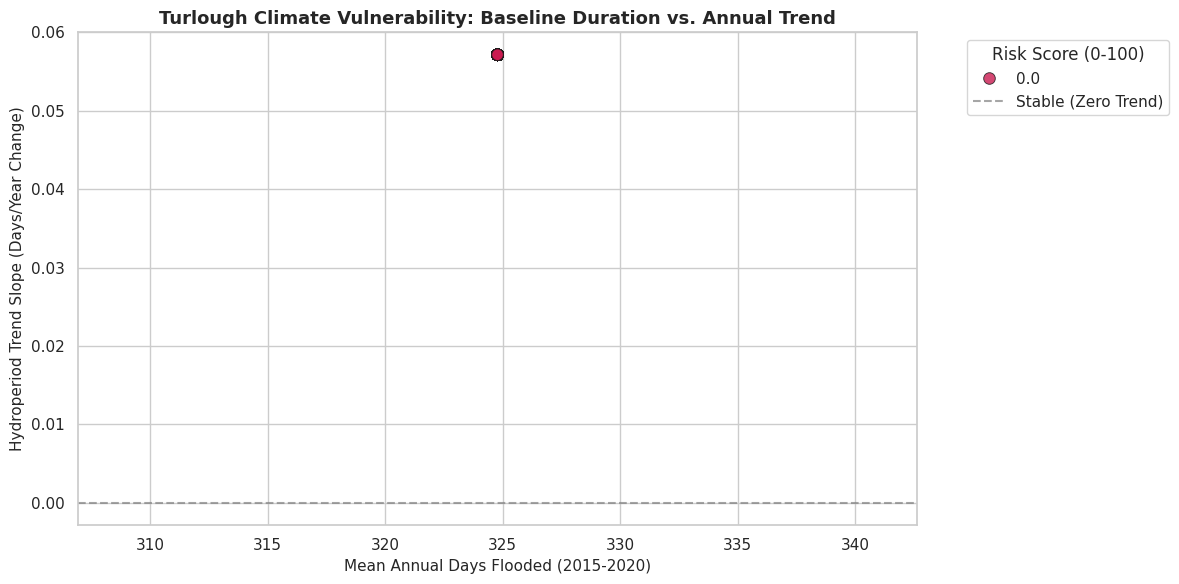

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Ensure df_long has proper datetime and Year columns
df_long['Date'] = pd.to_datetime(df_long['Date'])
df_long['Year'] = df_long['Date'].dt.year

# Define flooding threshold (e.g., > 0.05 meters considered flooded)
FLOOD_THRESHOLD = 0.05
df_long['Is_Flooded'] = df_long['Water_Level_Clean'] > FLOOD_THRESHOLD


# ==========================================
# 1. CALCULATE ANNUAL HYDROPERIOD MATRIX
# ==========================================
print("--- 1. Computing Annual Hydroperiods (2015-2020) ---")

# Sum up days flooded per turlough per year
annual_hydro = df_long.groupby(['Turlough_ID', 'Year'])['Is_Flooded'].sum().reset_index()
annual_hydro = annual_hydro.rename(columns={'Is_Flooded': 'Days_Flooded'})

# Pivot to create a Turlough x Year matrix
hydro_matrix = annual_hydro.pivot(index='Turlough_ID', columns='Year', values='Days_Flooded').fillna(0)
print(f"Hydroperiod matrix shape: {hydro_matrix.shape}")


# ==========================================
# 2. VULNERABILITY & DESICCATION RISK METRICS
# ==========================================
print("\n--- 2. Calculating Ecological Vulnerability Index (EVI) ---")

evi_df = pd.DataFrame(index=hydro_matrix.index)

# Metric A: Baseline hydroperiod (average days flooded across the 6 years)
evi_df['Mean_Days_Flooded'] = hydro_matrix.mean(axis=1)

# Metric B: Hydroperiod Trend Slope (measuring annual shortening/lengthening)
# A negative slope means the turlough is spending fewer days flooded year-over-year
available_years = [y for y in range(2015, 2021) if y in hydro_matrix.columns]

def calculate_slope(row):
    y = row[available_years].values
    x = np.arange(len(y))
    if len(y) < 3 or np.isnan(y).any():
        return 0
    slope, _ = np.polyfit(x, y, 1)
    return slope

evi_df['Hydroperiod_Trend_Slope'] = hydro_matrix.apply(calculate_slope, axis=1)

# Metric C: Inter-annual Volatility (Coefficient of Variation)
# High volatility indicates erratic, unstable filling patterns
evi_df['Hydroperiod_CV'] = hydro_matrix[available_years].std(axis=1) / (hydro_matrix[available_years].mean(axis=1) + 1e-5)

# Composite Ecological Vulnerability Index (0 to 100 Scale)
# Higher score = higher risk of climate stress / drying out
# Factors: Negative trend slope (drying) + Low baseline hydroperiod + High volatility
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 100))

# Create a risk score where shrinking hydroperiods and low water permanence score higher risk
risk_features = pd.DataFrame(index=evi_df.index)
risk_features['drying_pressure'] = -evi_df['Hydroperiod_Trend_Slope'] # more negative = higher risk
risk_features['short_duration'] = -evi_df['Mean_Days_Flooded'] # fewer days flooded = higher risk
risk_features['instability'] = evi_df['Hydroperiod_CV'] # higher volatility = higher risk

scaled_features = scaler.fit_transform(risk_features.fillna(0))
evi_df['Conservation_Risk_Score'] = scaled_features.mean(axis=1)

# Sort by highest risk score
evi_df = evi_df.sort_values(by='Conservation_Risk_Score', ascending=False)

print("\nTop 10 Most Ecologically Vulnerable / At-Risk Turloughs:")
display(evi_df.head(10))


# ==========================================
# 3. VISUALIZING CLIMATE VULNERABILITY
# ==========================================
plt.figure(figsize=(12, 6))

# Scatter plot: Mean Hydroperiod vs. Hydroperiod Trend Slope
sns.scatterplot(
    data=evi_df,
    x='Mean_Days_Flooded',
    y='Hydroperiod_Trend_Slope',
    hue='Conservation_Risk_Score',
    palette='rocket_r',
    s=70,
    alpha=0.8,
    edgecolor='k'
)

plt.axhline(0, color='gray', linestyle='--', alpha=0.7, label='Stable (Zero Trend)')
plt.title('Turlough Climate Vulnerability: Baseline Duration vs. Annual Trend', fontsize=13, fontweight='bold')
plt.xlabel('Mean Annual Days Flooded (2015-2020)', fontsize=11)
plt.ylabel('Hydroperiod Trend Slope (Days/Year Change)', fontsize=11)
plt.legend(title='Risk Score (0-100)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### Part 1: Prepare Time Series Sequences for Deep Learning
We will extract water level values for a single target turlough, normalize the values between 0 and 1, and structure the sequential dataset so that the network uses a sliding window of the past 30 days to predict the water level on day 31.

In [22]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Target a single highly-active turlough
target_turlough = '001BREDRM'
target_series = df_imputed_wide[target_turlough].values.reshape(-1, 1)

# 2. Normalize the data (Crucial for neural network convergence)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(target_series)

# 3. Create sliding sequences (30 days input -> 1 day output)
def create_sequences(data, seq_length=30):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 30
X, y = create_sequences(scaled_data, SEQ_LENGTH)

# 4. Chronological Train/Test Split (80% train, 20% test)
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(f"Training set size: {X_train_t.shape}")
print(f"Testing set size: {X_test_t.shape}")

Training set size: torch.Size([2314, 30, 1])
Testing set size: torch.Size([579, 30, 1])


### Part 2: Build and Train the LSTM Network
We define an LSTM network architecture containing an LSTM layer followed by a fully connected (Linear) layer to map the output to a single regression value.

In [23]:
class TurloughLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
        super(TurloughLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

# Initialize model, loss function, and optimizer
model = TurloughLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train the LSTM model
epochs = 100
batch_size = 64
losses = []

print("Training the LSTM network...")
model.train()
for epoch in range(epochs):
    epoch_loss = 0
    # Mini-batch loop
    permutation = torch.randperm(X_train_t.size(0))
    for i in range(0, X_train_t.size(0), batch_size):
        indices = permutation[i:i+batch_size]
        batch_x, batch_y = X_train_t[indices], y_train_t[indices]

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / (X_train_t.size(0) / batch_size)
    losses.append(avg_loss)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.6f}")

# Plot loss curve
plt.figure(figsize=(8, 3))
plt.plot(losses, color='darkred')
plt.title('LSTM Training Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.show()

Training the LSTM network...
Epoch [1/100] - Loss: 0.038374
Epoch [10/100] - Loss: 0.000206
Epoch [20/100] - Loss: 0.000072
Epoch [30/100] - Loss: 0.000040


KeyboardInterrupt: 

### Part 3: Evaluate and Visualize Forecast Predictions
We run predictions on the test dataset (which the model has never seen during training), scale the predictions back to the original water level units, and compare them against actual values.

Test Mean Absolute Error (MAE): 0.018 units
Test Root Mean Squared Error (RMSE): 0.026 units


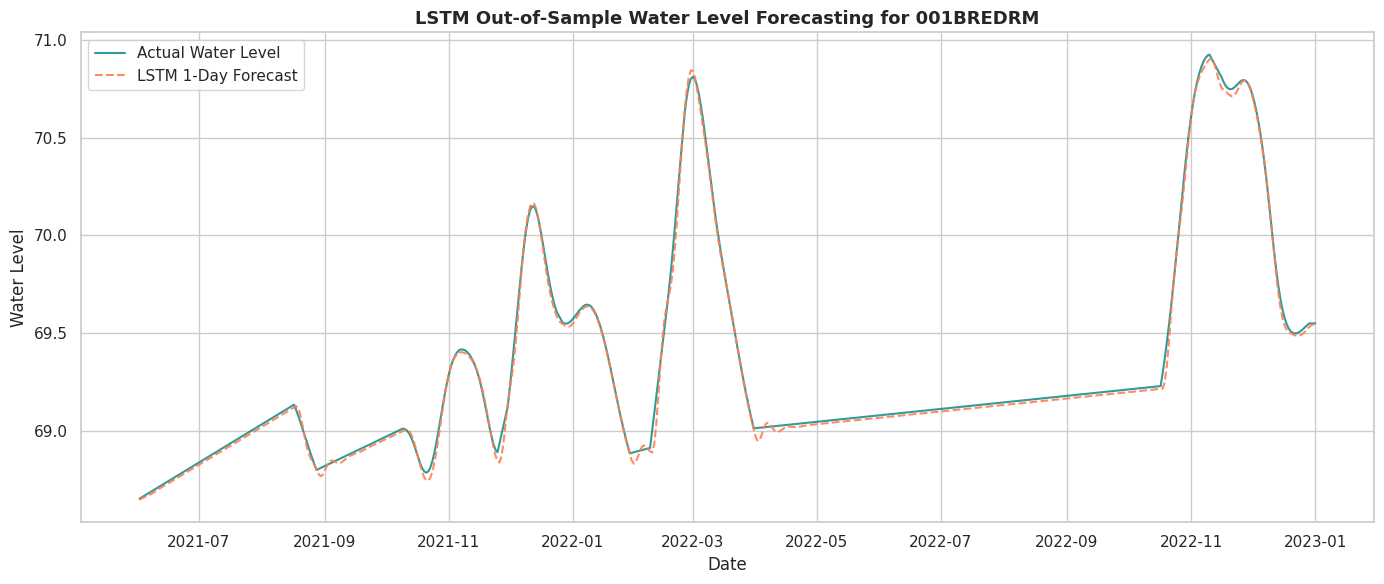

In [17]:
model.eval()
with torch.no_grad():
    test_predictions = model(X_test_t).numpy()

# Inverse transform predictions and actuals back to original water level units
predicted_vals = scaler.inverse_transform(test_predictions)
actual_vals = scaler.inverse_transform(y_test_t.numpy())

# Compute evaluation metrics
mae = np.mean(np.abs(predicted_vals - actual_vals))
rmse = np.sqrt(np.mean((predicted_vals - actual_vals)**2))
print(f"Test Mean Absolute Error (MAE): {mae:.3f} units")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.3f} units")

# Plot actual vs forecasted timeline
test_dates = df_imputed_wide.index[split_idx + SEQ_LENGTH:]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, actual_vals, label='Actual Water Level', color='teal', alpha=0.8)
plt.plot(test_dates, predicted_vals, label='LSTM 1-Day Forecast', color='coral', linestyle='--', alpha=0.9)
plt.title(f'LSTM Out-of-Sample Water Level Forecasting for {target_turlough}', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Water Level')
plt.legend()
plt.tight_layout()
plt.show()

### Multi-Site LSTM Forecasting
We will select 3 target turloughs, loop through them to scale their datasets, train separate LSTM models for each, and then plot the comparative predictions.

In [18]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Define model class again to ensure scope safety
class TurloughLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
        super(TurloughLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

# Select multiple target turloughs
target_turloughs = ['001BREDRM', '002CPLUNK', '003BRIFLD']
results = {}
SEQ_LENGTH = 30

for site in target_turloughs:
    print(f"\n{'='*40}\nTraining LSTM for site: {site}\n{'='*40}")

    # 1. Prepare Data
    series = df_imputed_wide[site].values.reshape(-1, 1)
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_data = scaler.fit_transform(series)

    xs, ys = [], []
    for i in range(len(scaled_data) - SEQ_LENGTH):
        xs.append(scaled_data[i:(i + SEQ_LENGTH)])
        ys.append(scaled_data[i + SEQ_LENGTH])
    X, y = np.array(xs), np.array(ys)

    split_idx = int(len(X) * 0.8)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # 2. Initialize Model
    model = TurloughLSTM()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # 3. Train Model (Running fewer epochs for speed across multiple sites)
    epochs = 40
    batch_size = 64
    model.train()
    for epoch in range(epochs):
        permutation = torch.randperm(X_train_t.size(0))
        for i in range(0, X_train_t.size(0), batch_size):
            indices = permutation[i:i+batch_size]
            batch_x, batch_y = X_train_t[indices], y_train_t[indices]
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # 4. Evaluate Model
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_t).numpy()

    predicted_vals = scaler.inverse_transform(test_preds)
    actual_vals = scaler.inverse_transform(y_test_t.numpy())

    mae = np.mean(np.abs(predicted_vals - actual_vals))
    rmse = np.sqrt(np.mean((predicted_vals - actual_vals)**2))
    print(f"{site} -> Test MAE: {mae:.3f} | Test RMSE: {rmse:.3f}")

    # Store results for plotting
    results[site] = {
        'actual': actual_vals,
        'predicted': predicted_vals,
        'dates': df_imputed_wide.index[split_idx + SEQ_LENGTH:]
    }


Training LSTM for site: 001BREDRM
001BREDRM -> Test MAE: 0.020 | Test RMSE: 0.036

Training LSTM for site: 002CPLUNK
002CPLUNK -> Test MAE: 0.027 | Test RMSE: 0.043

Training LSTM for site: 003BRIFLD
003BRIFLD -> Test MAE: 0.042 | Test RMSE: 0.081


### Plotting Comparative Multi-Site Forecasts
Now we generate a multi-panel visual timeline showing the predicted versus actual water levels across our chosen sites.

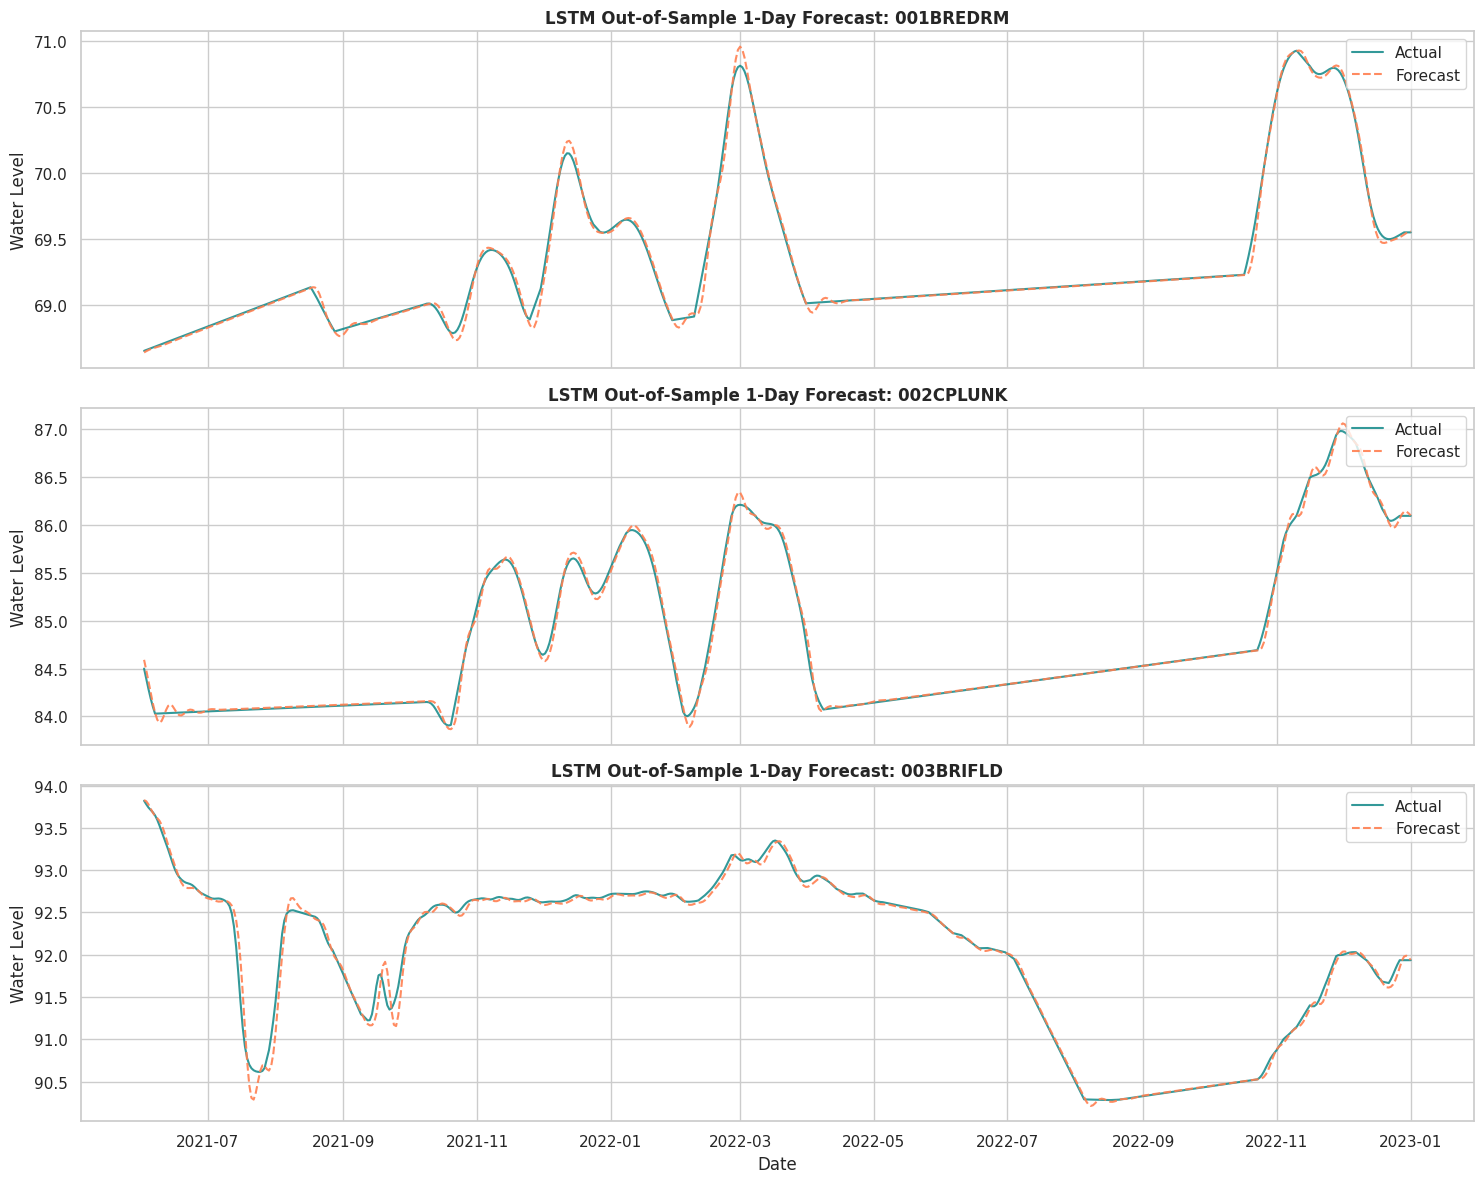

In [19]:
fig, axes = plt.subplots(len(target_turloughs), 1, figsize=(15, 4 * len(target_turloughs)), sharex=True)

for idx, site in enumerate(target_turloughs):
    site_res = results[site]
    ax = axes[idx] if len(target_turloughs) > 1 else axes

    ax.plot(site_res['dates'], site_res['actual'], label='Actual', color='teal', alpha=0.8)
    ax.plot(site_res['dates'], site_res['predicted'], label='Forecast', color='coral', linestyle='--', alpha=0.9)
    ax.set_title(f'LSTM Out-of-Sample 1-Day Forecast: {site}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Water Level')
    ax.legend(loc='upper right')

plt.xlabel('Date')
plt.tight_layout()
plt.show()

### 2015–2021 Training with 2022 Testing
In this section, we split the timeline chronologically. The model reads sequences exclusively from **2015 to 2021** for training, and we validate its predictive accuracy on the unseen year of **2022**.

In [20]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

target_turloughs = ['001BREDRM', '002CPLUNK', '003BRIFLD']
results_2022 = {}
SEQ_LENGTH = 30

# Ensure index is datetime
df_imputed_wide.index = pd.to_datetime(df_imputed_wide.index)

for site in target_turloughs:
    print(f"\n{'='*40}\nTraining on 2015-2021 & Testing on 2022 for: {site}\n{'='*40}")

    # 1. Chronological Split by Date
    train_series_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]]
    test_series_df = df_imputed_wide.loc[(df_imputed_wide.index >= '2022-01-01') & (df_imputed_wide.index <= '2022-12-31'), [site]]

    # If the test set requires lookback sequences from late 2021
    lookback_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]].tail(SEQ_LENGTH)
    extended_test_df = pd.concat([lookback_df, test_series_df])

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_train = scaler.fit_transform(train_series_df.values)
    scaled_test = scaler.transform(extended_test_df.values)

    # 2. Build Sequence Batches
    def to_sequences(data):
        xs, ys = [], []
        for i in range(len(data) - SEQ_LENGTH):
            xs.append(data[i:(i + SEQ_LENGTH)])
            ys.append(data[i + SEQ_LENGTH])
        return np.array(xs), np.array(ys)

    X_train, y_train = to_sequences(scaled_train)
    X_test, y_test = to_sequences(scaled_test)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # 3. Train Model
    model = TurloughLSTM()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    epochs = 45
    batch_size = 64
    model.train()
    for epoch in range(epochs):
        permutation = torch.randperm(X_train_t.size(0))
        for i in range(0, X_train_t.size(0), batch_size):
            indices = permutation[i:i+batch_size]
            batch_x, batch_y = X_train_t[indices], y_train_t[indices]
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # 4. Out-of-Sample Predictions
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_t).numpy()

    predicted_vals = scaler.inverse_transform(test_preds)
    actual_vals = scaler.inverse_transform(y_test_t.numpy())

    mae = np.mean(np.abs(predicted_vals - actual_vals))
    rmse = np.sqrt(np.mean((predicted_vals - actual_vals)**2))
    print(f"{site} -> 2022 Test MAE: {mae:.3f} | Test RMSE: {rmse:.3f}")

    results_2022[site] = {
        'actual': actual_vals,
        'predicted': predicted_vals,
        'dates': test_series_df.index
    }


Training on 2015-2021 & Testing on 2022 for: 001BREDRM
001BREDRM -> 2022 Test MAE: 0.022 | Test RMSE: 0.035

Training on 2015-2021 & Testing on 2022 for: 002CPLUNK
002CPLUNK -> 2022 Test MAE: 0.027 | Test RMSE: 0.039

Training on 2015-2021 & Testing on 2022 for: 003BRIFLD
003BRIFLD -> 2022 Test MAE: 0.022 | Test RMSE: 0.029


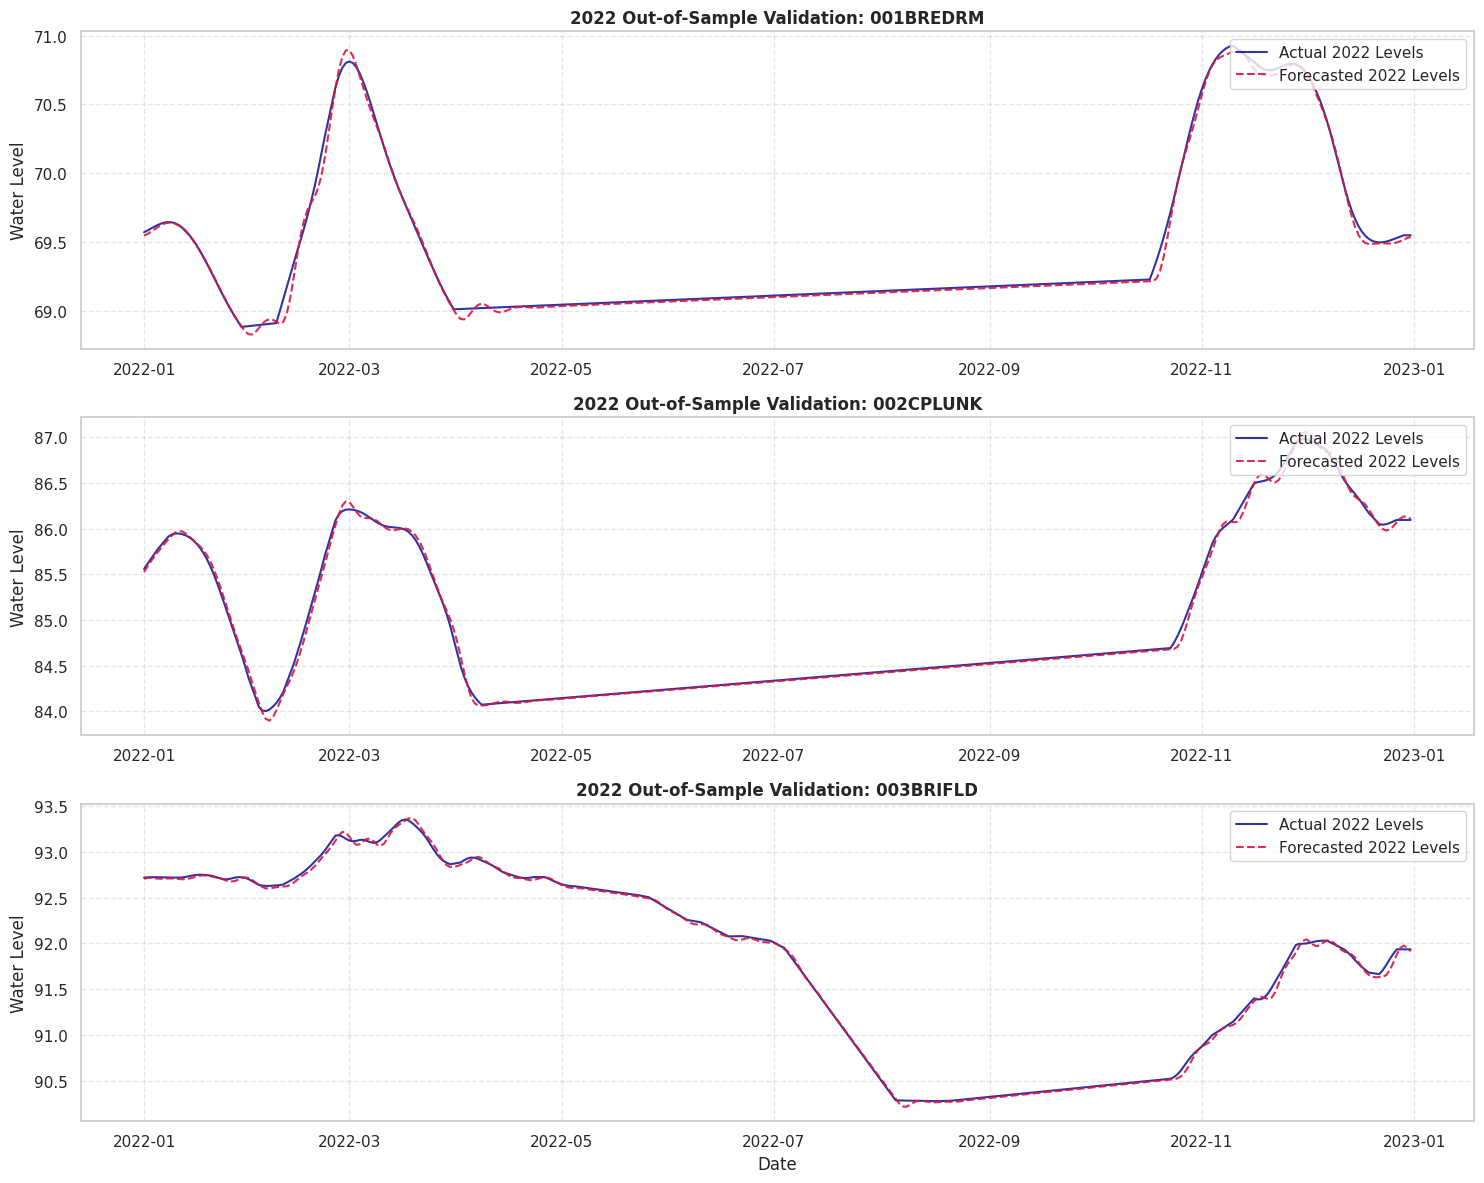

In [21]:
fig, axes = plt.subplots(len(target_turloughs), 1, figsize=(15, 4 * len(target_turloughs)), sharex=False)

for idx, site in enumerate(target_turloughs):
    site_res = results_2022[site]
    ax = axes[idx] if len(target_turloughs) > 1 else axes

    ax.plot(site_res['dates'], site_res['actual'], label='Actual 2022 Levels', color='darkblue', alpha=0.8)
    ax.plot(site_res['dates'], site_res['predicted'], label='Forecasted 2022 Levels', color='crimson', linestyle='--', alpha=0.9)
    ax.set_title(f'2022 Out-of-Sample Validation: {site}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Water Level')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

### Part 4: Multi-Step Ahead Forecasting (7-Day Horizon)
Here, we define a sequence generator that maps a lookback window of 30 days to a target sequence of 7 days. We adjust our LSTM model's output layer to match this 7-day projection horizon.

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Update the LSTM Network to output multiple steps
class MultiStepTurloughLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_horizon=7):
        super(MultiStepTurloughLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_horizon)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :]) # Predict multi-step horizon from the last hidden state
        return out

target_turloughs = ['001BREDRM', '002CPLUNK', '003BRIFLD']
results_multi = {}
SEQ_LENGTH = 30
FORECAST_HORIZON = 7

for site in target_turloughs:
    print(f"\n{'='*40}\nTraining 7-Day LSTM for site: {site}\n{'='*40}")

    # Split 2015-2021 for Train and 2022 for Test
    train_series_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]]
    test_series_df = df_imputed_wide.loc[(df_imputed_wide.index >= '2022-01-01') & (df_imputed_wide.index <= '2022-12-31'), [site]]

    # Extend test lookback window
    lookback_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]].tail(SEQ_LENGTH)
    extended_test_df = pd.concat([lookback_df, test_series_df])

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_train = scaler.fit_transform(train_series_df.values)
    scaled_test = scaler.transform(extended_test_df.values)

    # 2. Modify sequence function to handle 7-day targets
    def to_multistep_sequences(data, seq_length=30, horizon=7):
        xs, ys = [], []
        for i in range(len(data) - seq_length - horizon + 1):
            xs.append(data[i:(i + seq_length)])
            ys.append(data[(i + seq_length):(i + seq_length + horizon), 0])
        return np.array(xs), np.array(ys)

    X_train, y_train = to_multistep_sequences(scaled_train, SEQ_LENGTH, FORECAST_HORIZON)
    X_test, y_test = to_multistep_sequences(scaled_test, SEQ_LENGTH, FORECAST_HORIZON)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # 3. Train multi-step model
    model = MultiStepTurloughLSTM(output_horizon=FORECAST_HORIZON)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    epochs = 45
    batch_size = 64
    model.train()
    for epoch in range(epochs):
        permutation = torch.randperm(X_train_t.size(0))
        for i in range(0, X_train_t.size(0), batch_size):
            indices = permutation[i:i+batch_size]
            batch_x, batch_y = X_train_t[indices], y_train_t[indices]
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # 4. Predict on Test data
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_t).numpy()

    # De-normalize predictions
    predicted_vals = scaler.inverse_transform(test_preds)
    actual_vals = scaler.inverse_transform(y_test_t.numpy())

    # Calculate overall average metrics across all 7 steps
    mae = np.mean(np.abs(predicted_vals - actual_vals))
    rmse = np.sqrt(np.mean((predicted_vals - actual_vals)**2))
    print(f"{site} -> Mean Multi-Step (7-Day) MAE: {mae:.3f} | RMSE: {rmse:.3f}")

    # We will preserve the alignment with the actual dates
    results_multi[site] = {
        'actual': actual_vals,
        'predicted': predicted_vals,
        'dates': test_series_df.index[:len(actual_vals)]
    }


Training 7-Day LSTM for site: 001BREDRM
001BREDRM -> Mean Multi-Step (7-Day) MAE: 0.053 | RMSE: 0.108

Training 7-Day LSTM for site: 002CPLUNK


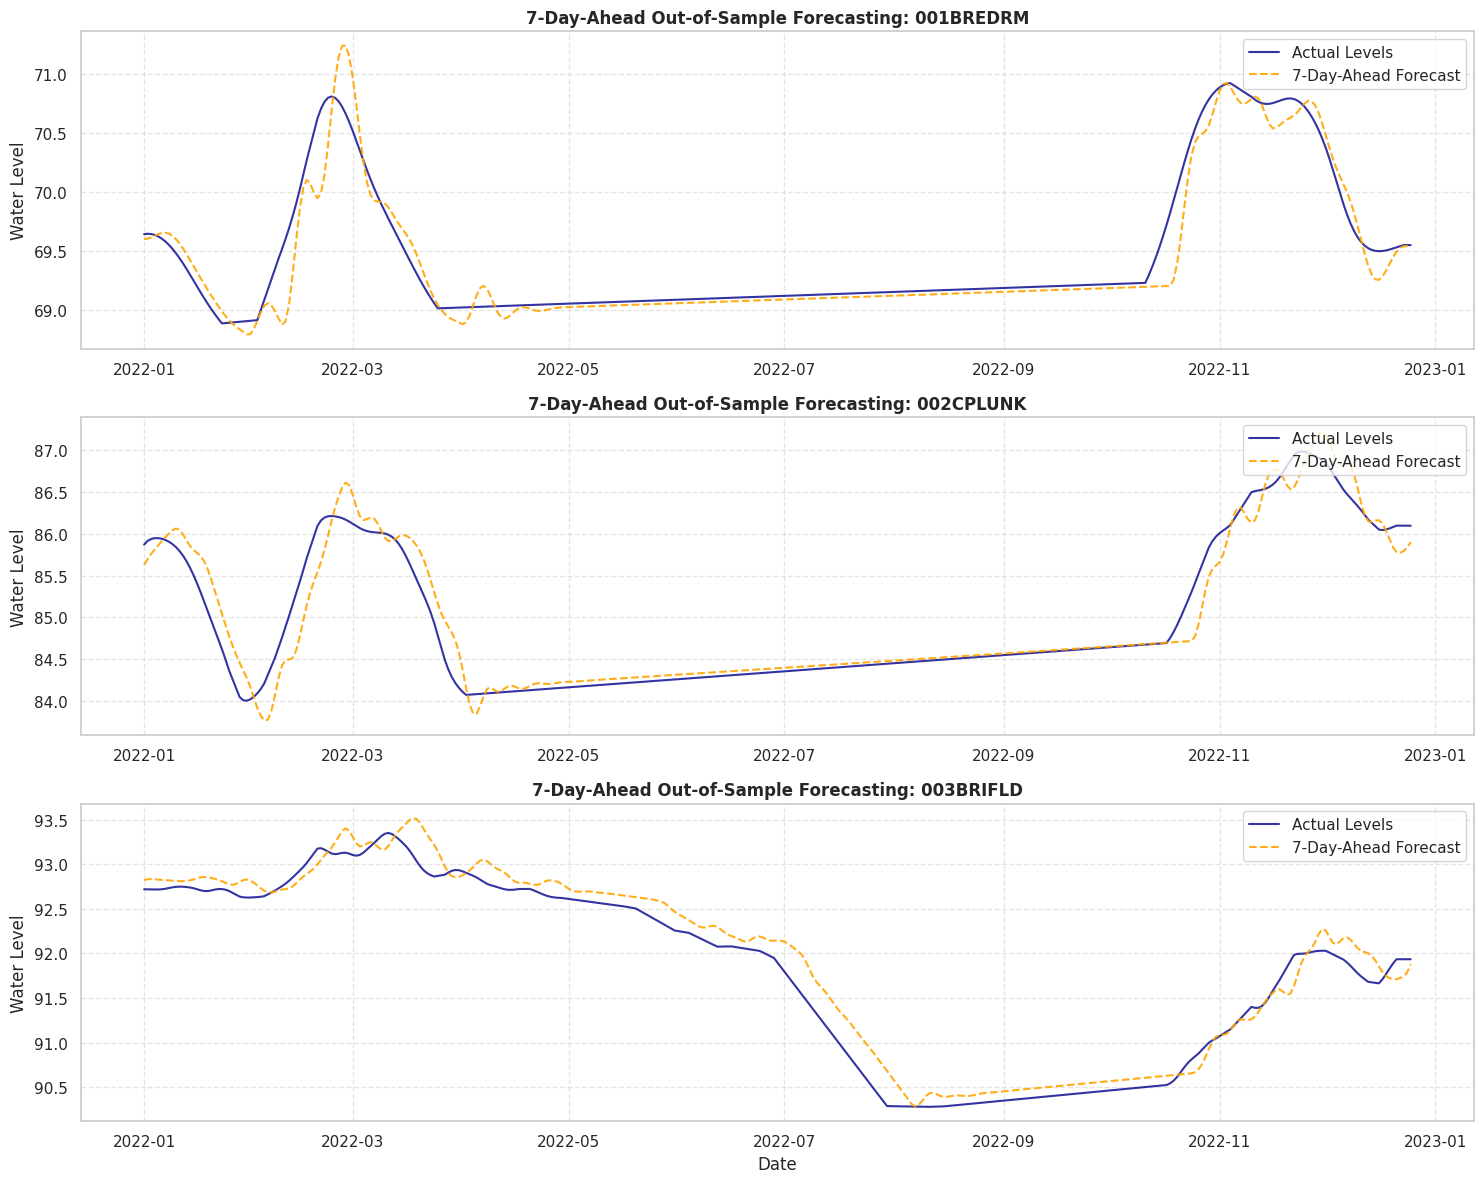

In [25]:
# Visualize the actual vs forecasted levels for Day 7 (longest forecast horizon)
fig, axes = plt.subplots(len(target_turloughs), 1, figsize=(15, 4 * len(target_turloughs)), sharex=False)

for idx, site in enumerate(target_turloughs):
    site_res = results_multi[site]
    ax = axes[idx] if len(target_turloughs) > 1 else axes

    # Index of 6 corresponds to Day +7 prediction
    day_7_actual = site_res['actual'][:, 6]
    day_7_predicted = site_res['predicted'][:, 6]

    ax.plot(site_res['dates'], day_7_actual, label='Actual Levels', color='darkblue', alpha=0.8)
    ax.plot(site_res['dates'], day_7_predicted, label='7-Day-Ahead Forecast', color='orange', linestyle='--', alpha=0.9)
    ax.set_title(f'7-Day-Ahead Out-of-Sample Forecasting: {site}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Water Level')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

### Quantitative Analysis of Forecasting Degradation (Step-by-Step Error)
To measure how the predictive performance degrades over our 7-day horizon, we calculate the MAE and RMSE separately for each step ($t+1, t+2, \dots, t+7$) across our target sites.

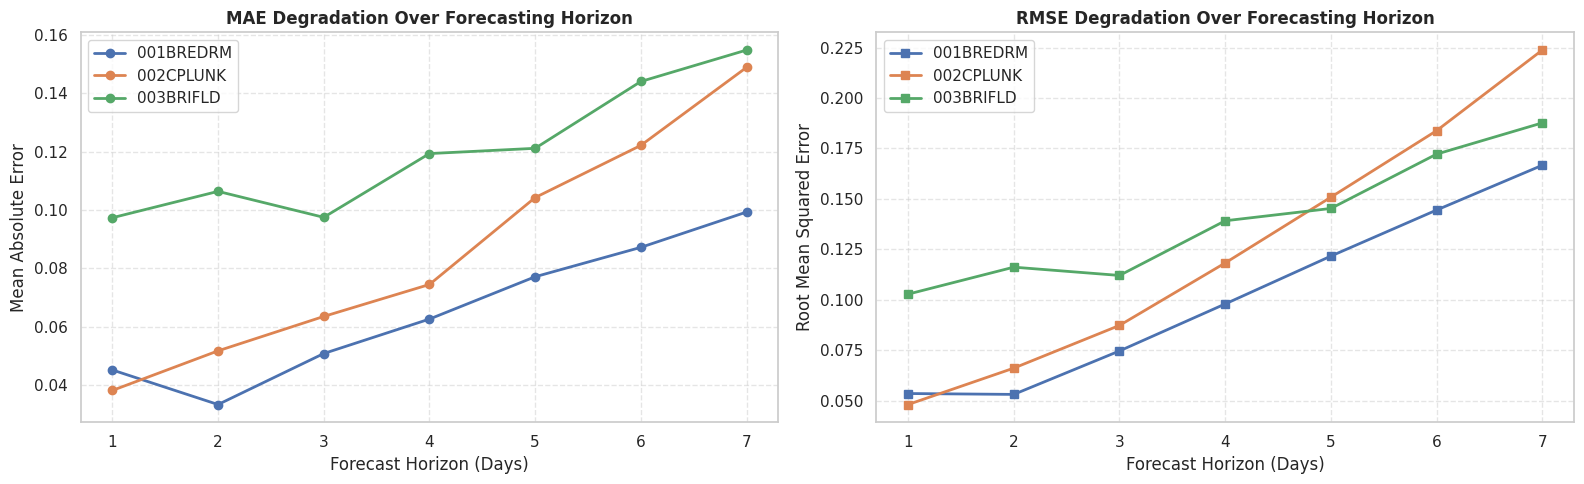

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

step_metrics = []

for site in target_turloughs:
    site_res = results_multi[site]
    actuals = site_res['actual']
    preds = site_res['predicted']

    # Calculate error for each step (0 to 6 corresponds to Day 1 to Day 7)
    for step in range(7):
        step_actual = actuals[:, step]
        step_pred = preds[:, step]

        mae = np.mean(np.abs(step_actual - step_pred))
        rmse = np.sqrt(np.mean((step_actual - step_pred)**2))

        step_metrics.append({
            'Site': site,
            'Horizon (Days)': step + 1,
            'MAE': mae,
            'RMSE': rmse
        })

df_steps = pd.DataFrame(step_metrics)

# Plot the performance degradation over the 7-day horizon
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# MAE Degradation Plot
for site in target_turloughs:
    site_df = df_steps[df_steps['Site'] == site]
    axes[0].plot(site_df['Horizon (Days)'], site_df['MAE'], marker='o', label=site, linewidth=2)
axes[0].set_title('MAE Degradation Over Forecasting Horizon', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Forecast Horizon (Days)')
axes[0].set_ylabel('Mean Absolute Error')
axes[0].set_xticks(range(1, 8))
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# RMSE Degradation Plot
for site in target_turloughs:
    site_df = df_steps[df_steps['Site'] == site]
    axes[1].plot(site_df['Horizon (Days)'], site_df['RMSE'], marker='s', label=site, linewidth=2)
axes[1].set_title('RMSE Degradation Over Forecasting Horizon', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Forecast Horizon (Days)')
axes[1].set_ylabel('Root Mean Squared Error')
axes[1].set_xticks(range(1, 8))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

### Part 5: GRU vs. LSTM Performance Comparison
We will define and train a Gated Recurrent Unit (GRU) network on the exact same multi-step (7-day ahead) sequence prediction task for our target turloughs, allowing us to quantitatively compare its convergence speed and predictive accuracy against the LSTM.

In [27]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Define the Multi-Step GRU Network
class MultiStepTurloughGRU(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_horizon=7):
        super(MultiStepTurloughGRU, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_horizon)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)
        out = self.fc(out[:, -1, :])
        return out

gru_results = {}
SEQ_LENGTH = 30
FORECAST_HORIZON = 7

for site in target_turloughs:
    print(f"\nTraining 7-Day GRU for site: {site}")

    # Prepare Data split (identical to LSTM split)
    train_series_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]]
    test_series_df = df_imputed_wide.loc[(df_imputed_wide.index >= '2022-01-01') & (df_imputed_wide.index <= '2022-12-31'), [site]]
    lookback_df = df_imputed_wide.loc[df_imputed_wide.index < '2022-01-01', [site]].tail(SEQ_LENGTH)
    extended_test_df = pd.concat([lookback_df, test_series_df])

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaled_train = scaler.fit_transform(train_series_df.values)
    scaled_test = scaler.transform(extended_test_df.values)

    X_train, y_train = to_multistep_sequences(scaled_train, SEQ_LENGTH, FORECAST_HORIZON)
    X_test, y_test = to_multistep_sequences(scaled_test, SEQ_LENGTH, FORECAST_HORIZON)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # Train GRU Model
    model_gru = MultiStepTurloughGRU(output_horizon=FORECAST_HORIZON)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model_gru.parameters(), lr=0.001)

    epochs = 45
    batch_size = 64
    model_gru.train()
    for epoch in range(epochs):
        permutation = torch.randperm(X_train_t.size(0))
        for i in range(0, X_train_t.size(0), batch_size):
            indices = permutation[i:i+batch_size]
            batch_x, batch_y = X_train_t[indices], y_train_t[indices]
            optimizer.zero_grad()
            outputs = model_gru(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # Predict on Test data
    model_gru.eval()
    with torch.no_grad():
        test_preds = model_gru(X_test_t).numpy()

    predicted_vals = scaler.inverse_transform(test_preds)
    actual_vals = scaler.inverse_transform(y_test_t.numpy())

    # Store metrics
    gru_results[site] = {
        'actual': actual_vals,
        'predicted': predicted_vals,
        'dates': test_series_df.index[:len(actual_vals)]
    }

# Compile comparison table
comparison_records = []
for site in target_turloughs:
    lstm_res = results_multi[site]
    gru_res = gru_results[site]

    lstm_mae = np.mean(np.abs(lstm_res['actual'] - lstm_res['predicted']))
    gru_mae = np.mean(np.abs(gru_res['actual'] - gru_res['predicted']))

    comparison_records.append({
        'Site': site,
        'LSTM MAE': lstm_mae,
        'GRU MAE': gru_mae,
        'Improvement (%)': ((lstm_mae - gru_mae) / lstm_mae) * 100
    })

display(pd.DataFrame(comparison_records))


Training 7-Day GRU for site: 001BREDRM

Training 7-Day GRU for site: 002CPLUNK

Training 7-Day GRU for site: 003BRIFLD


,Site,LSTM MAE,GRU MAE,Improvement (%)
0,001BREDRM,0.065129,0.066749,-2.486867
1,002CPLUNK,0.086178,0.076439,11.301589
2,003BRIFLD,0.120040,0.056829,52.657936


### Part 6: Continuous Wavelet Transform & Hydrological Coherence
We will analyze the frequency-dependent components of our water level signals using the Continuous Wavelet Transform (CWT) with a Morlet wavelet. This allows us to map how dominant periodicities (e.g., weekly, monthly, seasonal, or storm-scale cycles) shift over time and identify transient synchronization between subterranean systems during extreme events like Storm Desmond.

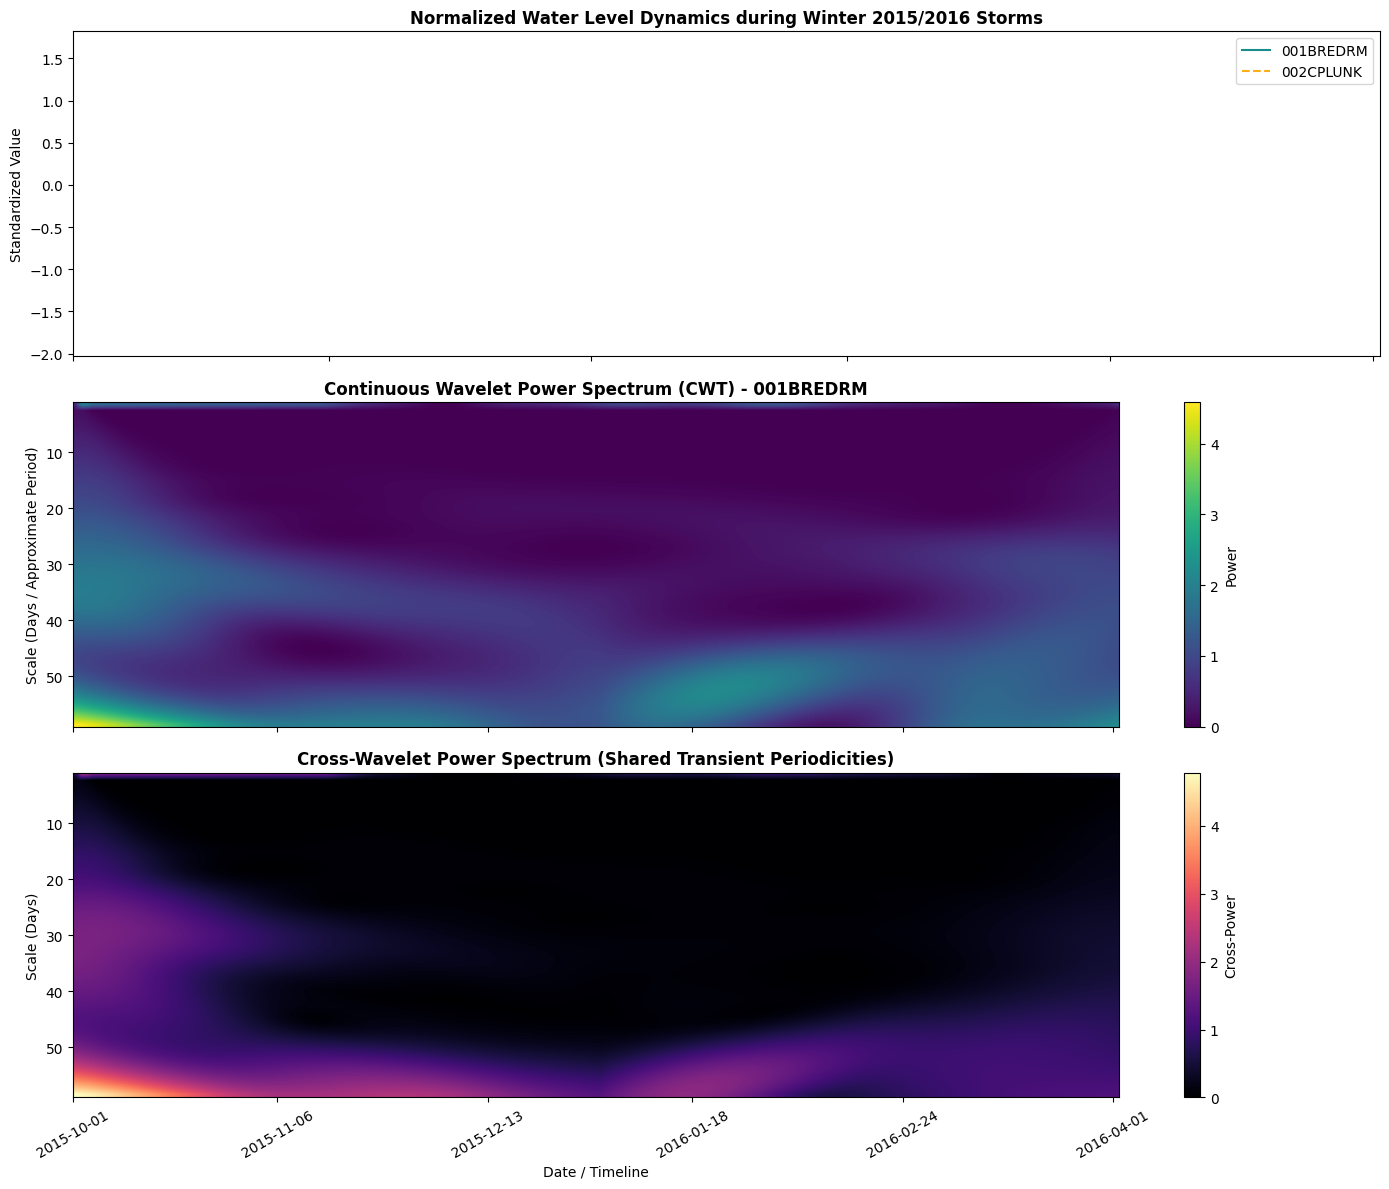

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Safely reconstruct df_imputed_wide if it's missing from active session memory
if 'df_imputed_wide' not in globals() or df_imputed_wide is None:
    print("df_imputed_wide not found in memory. Reconstructing from source CSV...")
    csv_path = '/content/20230804165658_combined_results_out.csv'
    if not os.path.exists(csv_path):
        csv_path = '/content/20230804165658_combined_results_out (1).csv'

    df_raw = pd.read_csv(csv_path)
    df_raw.rename(columns={df_raw.columns[0]: 'Date'}, inplace=True)
    df_raw['Date'] = pd.to_datetime(df_raw['Date'])
    df_pivot = df_raw.set_index('Date')
    df_imputed_wide = df_pivot.interpolate(method='linear', limit_direction='both').fillna(0)

# Choose two highly synchronized/active stations from our conduit and rate analysis
site_a = '001BREDRM'
site_b = '002CPLUNK'

# Ensure index is datetime
df_imputed_wide.index = pd.to_datetime(df_imputed_wide.index)

# Extract time series during the major Winter Storm Desmond window (Late 2015 - Early 2016)
storm_window = df_imputed_wide.loc['2015-10-01':'2016-04-01']
time_values = storm_window.index
sig_a = storm_window[site_a].values
sig_b = storm_window[site_b].values

# Standardize signals to compare relative fluctuations
sig_a_norm = (sig_a - np.mean(sig_a)) / np.std(sig_a)
sig_b_norm = (sig_b - np.mean(sig_b)) / np.std(sig_b)

# Define widths/scales for Morlet Wavelet Transform (ranging from daily up to ~2 months scales)
widths = np.arange(1, 60)

# Define a manual Morlet wavelet function to avoid SciPy version issues
def morlet_cwt(signal, scales, w0=5.0):
    n = len(signal)
    cwt_matrix = np.zeros((len(scales), n), dtype=complex)
    t = np.arange(-n//2, n//2)

    for idx, scale in enumerate(scales):
        t_scaled = t / scale
        wavelet = (np.pi**(-0.25)) * np.exp(1j * w0 * t_scaled) * np.exp(-0.5 * (t_scaled**2))
        wavelet /= np.sqrt(scale)
        conv = np.convolve(signal, wavelet, mode='same')
        cwt_matrix[idx, :] = conv
    return cwt_matrix

# Compute CWT using the robust custom Morlet wavelet
cwt_a = morlet_cwt(sig_a_norm, widths)
cwt_b = morlet_cwt(sig_b_norm, widths)

# Compute Cross-Wavelet Power (Spectral Density)
xwt = cwt_a * np.conj(cwt_b)
xwt_power = np.abs(xwt)

# Visualize the Wavelet Power Spectrum
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Plot original standardized series
axes[0].plot(time_values, sig_a_norm, label=site_a, color='teal', alpha=0.9)
axes[0].plot(time_values, sig_b_norm, label=site_b, color='orange', alpha=0.9, linestyle='--')
axes[0].set_title('Normalized Water Level Dynamics during Winter 2015/2016 Storms', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Standardized Value')
axes[0].legend()
axes[0].set_ylim(min(np.min(sig_a_norm), np.min(sig_b_norm)) - 0.5, max(np.max(sig_a_norm), np.max(sig_b_norm)) + 0.5)

# Plot Wavelet Power Spectrum for Site A
im1 = axes[1].imshow(np.abs(cwt_a)**2, extent=[0, len(time_values), widths[-1], widths[0]],
                     cmap='viridis', aspect='auto', interpolation='bilinear')
axes[1].set_title(f'Continuous Wavelet Power Spectrum (CWT) - {site_a}', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Scale (Days / Approximate Period)')
fig.colorbar(im1, ax=axes[1], label='Power')

# Plot Cross-Wavelet Power Spectrum (Coherence Zone)
im2 = axes[2].imshow(xwt_power, extent=[0, len(time_values), widths[-1], widths[0]],
                     cmap='magma', aspect='auto', interpolation='bilinear')
axes[2].set_title(f'Cross-Wavelet Power Spectrum (Shared Transient Periodicities)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Scale (Days)')
axes[2].set_xlabel('Date / Timeline')
fig.colorbar(im2, ax=axes[2], label='Cross-Power')

# Re-label X-axis with actual dates
tick_positions = np.linspace(0, len(time_values) - 1, 6, dtype=int)
tick_labels = [time_values[p].strftime('%Y-%m-%d') for p in tick_positions]
plt.xticks(tick_positions, tick_labels, rotation=30)

plt.tight_layout()
plt.show()